<a href="https://colab.research.google.com/github/juliaBerserk/rea-artificial-intelligence-systems-tasks/blob/main/Task1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [10]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
%matplotlib inline
sns.set(style="ticks")

In [13]:
data = pd.read_csv('/content/datatraining.txt', sep=",")

In [15]:
# Первые 5 строк датасета
data.head()

,date,Temperature,Humidity,Light,CO2,HumidityRatio,Occupancy
1,2015-02-04 17:51:00,23.18,27.2720,426.0,721.25,0.004793,1
2,2015-02-04 17:51:59,23.15,27.2675,429.5,714.00,0.004783,1
3,2015-02-04 17:53:00,23.15,27.2450,426.0,713.50,0.004779,1
4,2015-02-04 17:54:00,23.15,27.2000,426.0,708.25,0.004772,1
5,2015-02-04 17:55:00,23.10,27.2000,426.0,704.50,0.004757,1


In [16]:
# Размер датасета - 8143 строк, 7 колонок
data.shape
total_count = data.shape[0]
print('Всего строк: {}'.format(total_count))

Всего строк: 8143


In [17]:
# Список колонок
data.columns

Index(['date', 'Temperature', 'Humidity', 'Light', 'CO2', 'HumidityRatio',
       'Occupancy'],
      dtype='object')

In [18]:
# Проверим наличие пустых значений
# Цикл по колонкам датасета
for col in data.columns:
    # Количество пустых значений - все значения заполнены
    temp_null_count = data[data[col].isnull()].shape[0]
    print('{} - {}'.format(col, temp_null_count))

date - 0
Temperature - 0
Humidity - 0
Light - 0
CO2 - 0
HumidityRatio - 0
Occupancy - 0


In [19]:
# Основные статистические характеристки набора данных
data.describe()


,Temperature,Humidity,Light,CO2,HumidityRatio,Occupancy
count,8143.000000,8143.000000,8143.000000,8143.000000,8143.000000,8143.000000
mean,20.619084,25.731507,119.519375,606.546243,0.003863,0.212330
std,1.016916,5.531211,194.755805,314.320877,0.000852,0.408982
min,19.000000,16.745000,0.000000,412.750000,0.002674,0.000000
25%,19.700000,20.200000,0.000000,439.000000,0.003078,0.000000
50%,20.390000,26.222500,0.000000,453.500000,0.003801,0.000000
75%,21.390000,30.533333,256.375000,638.833333,0.004352,0.000000
max,23.180000,39.117500,1546.333333,2028.500000,0.006476,1.000000


In [20]:
# Определим уникальные значения для целевого признака
data['Occupancy'].unique()


array([1, 0])

<Axes: xlabel='Humidity', ylabel='HumidityRatio'>

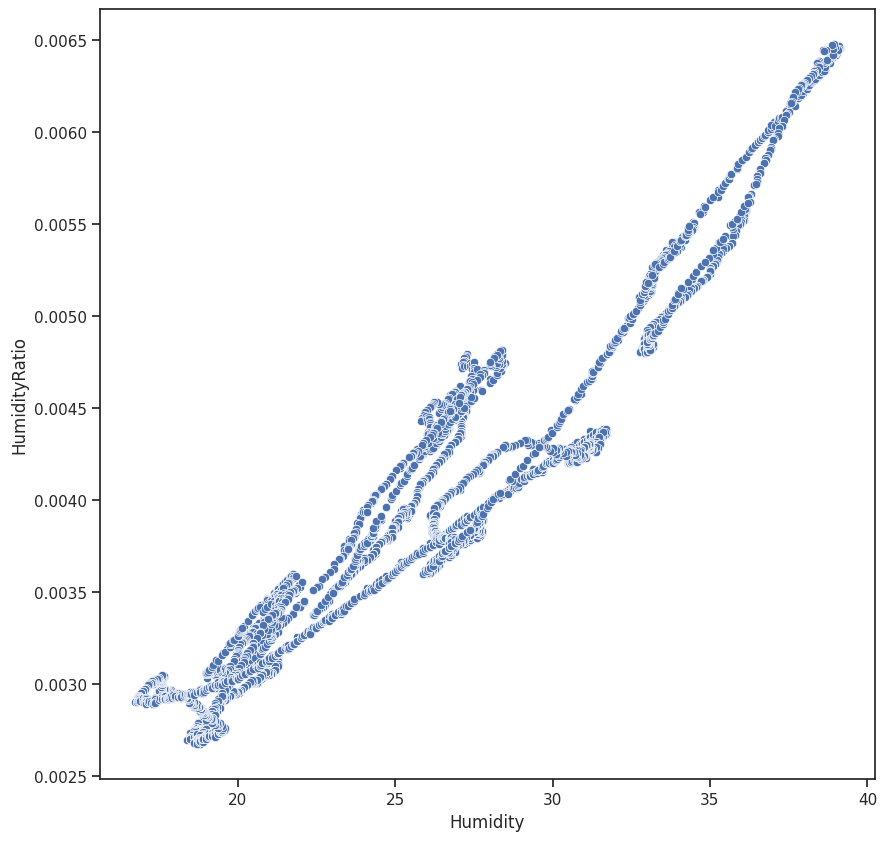

In [21]:
fig, ax = plt.subplots(figsize=(10,10))
sns.scatterplot(ax=ax, x='Humidity', y='HumidityRatio', data=data)


<Axes: xlabel='Humidity', ylabel='HumidityRatio'>

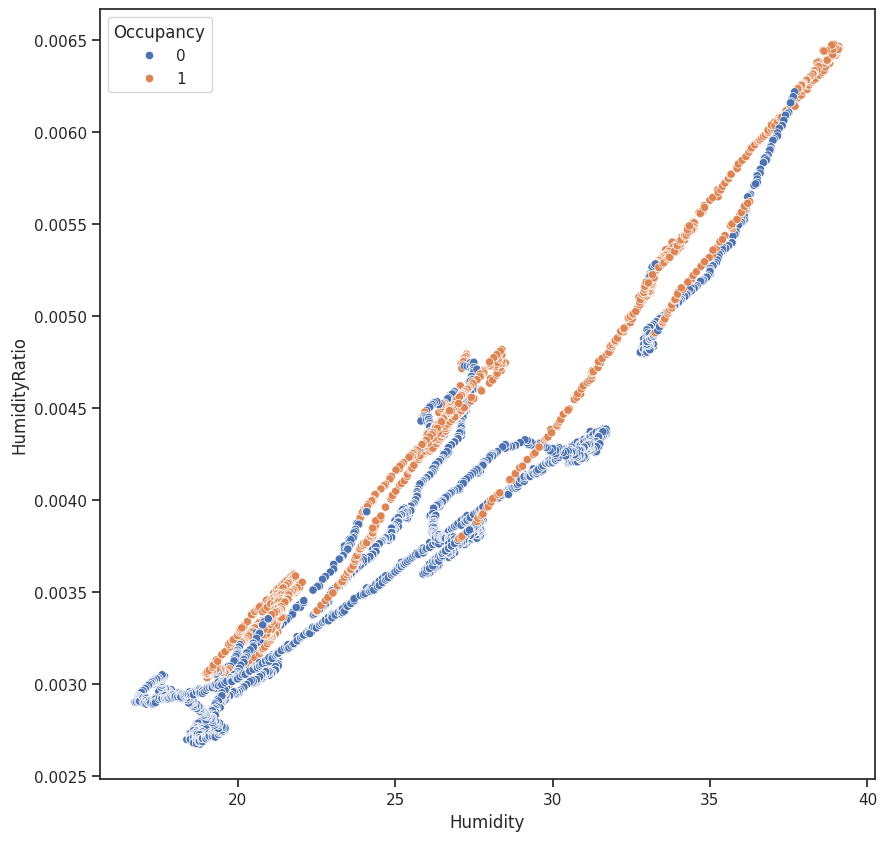

In [22]:
fig, ax = plt.subplots(figsize=(10,10))
sns.scatterplot(ax=ax, x='Humidity', y='HumidityRatio', data=data, hue='Occupancy')


/tmp/ipykernel_1332/3705192993.py:3: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(data['Humidity'])


<Axes: xlabel='Humidity', ylabel='Density'>

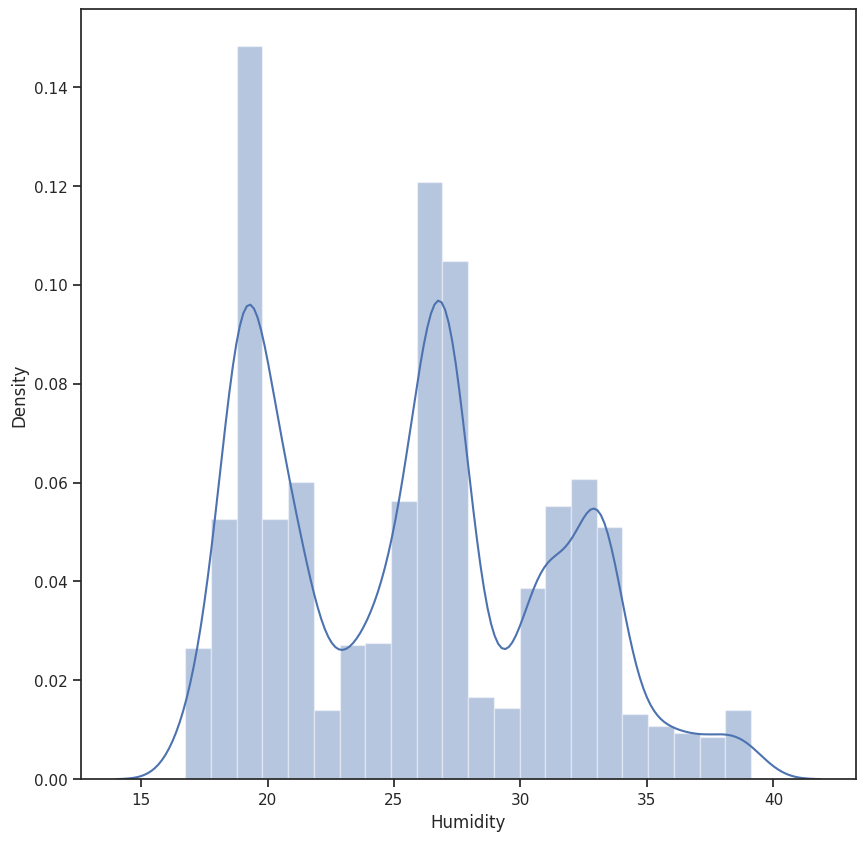

In [23]:
# гистограмма
fig, ax = plt.subplots(figsize=(10,10))
sns.distplot(data['Humidity'])

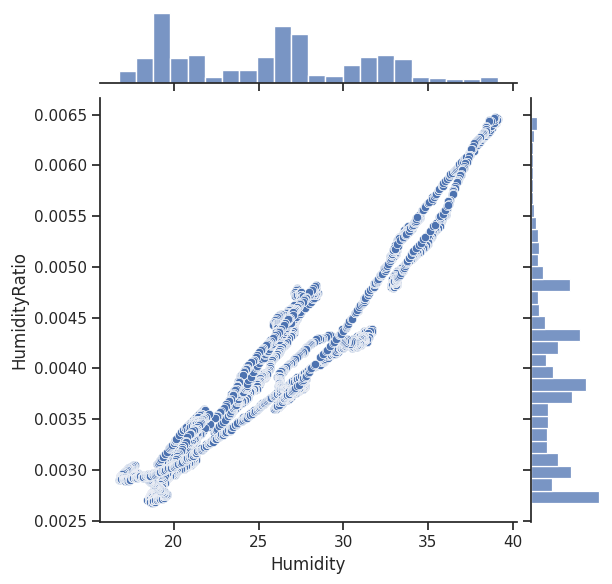

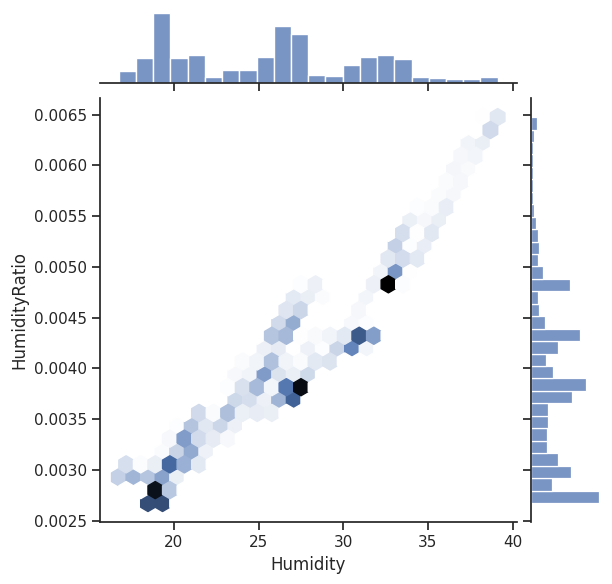

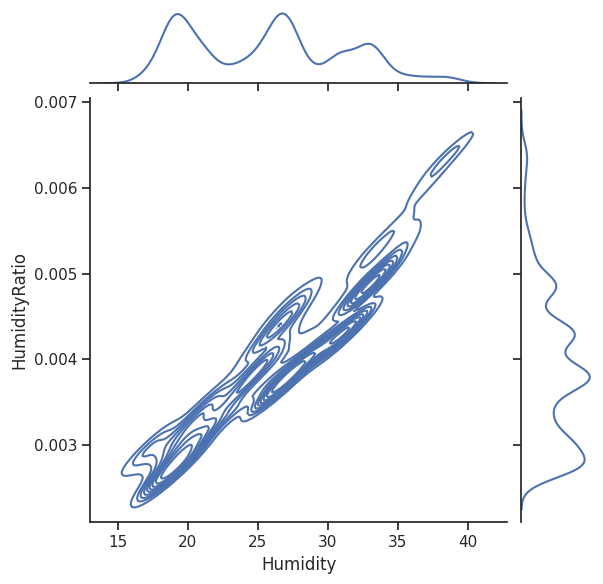

In [24]:
sns.jointplot(x='Humidity', y='HumidityRatio', data=data)
sns.jointplot(x='Humidity', y='HumidityRatio', data=data, kind="hex")
sns.jointplot(x='Humidity', y='HumidityRatio', data=data, kind="kde")


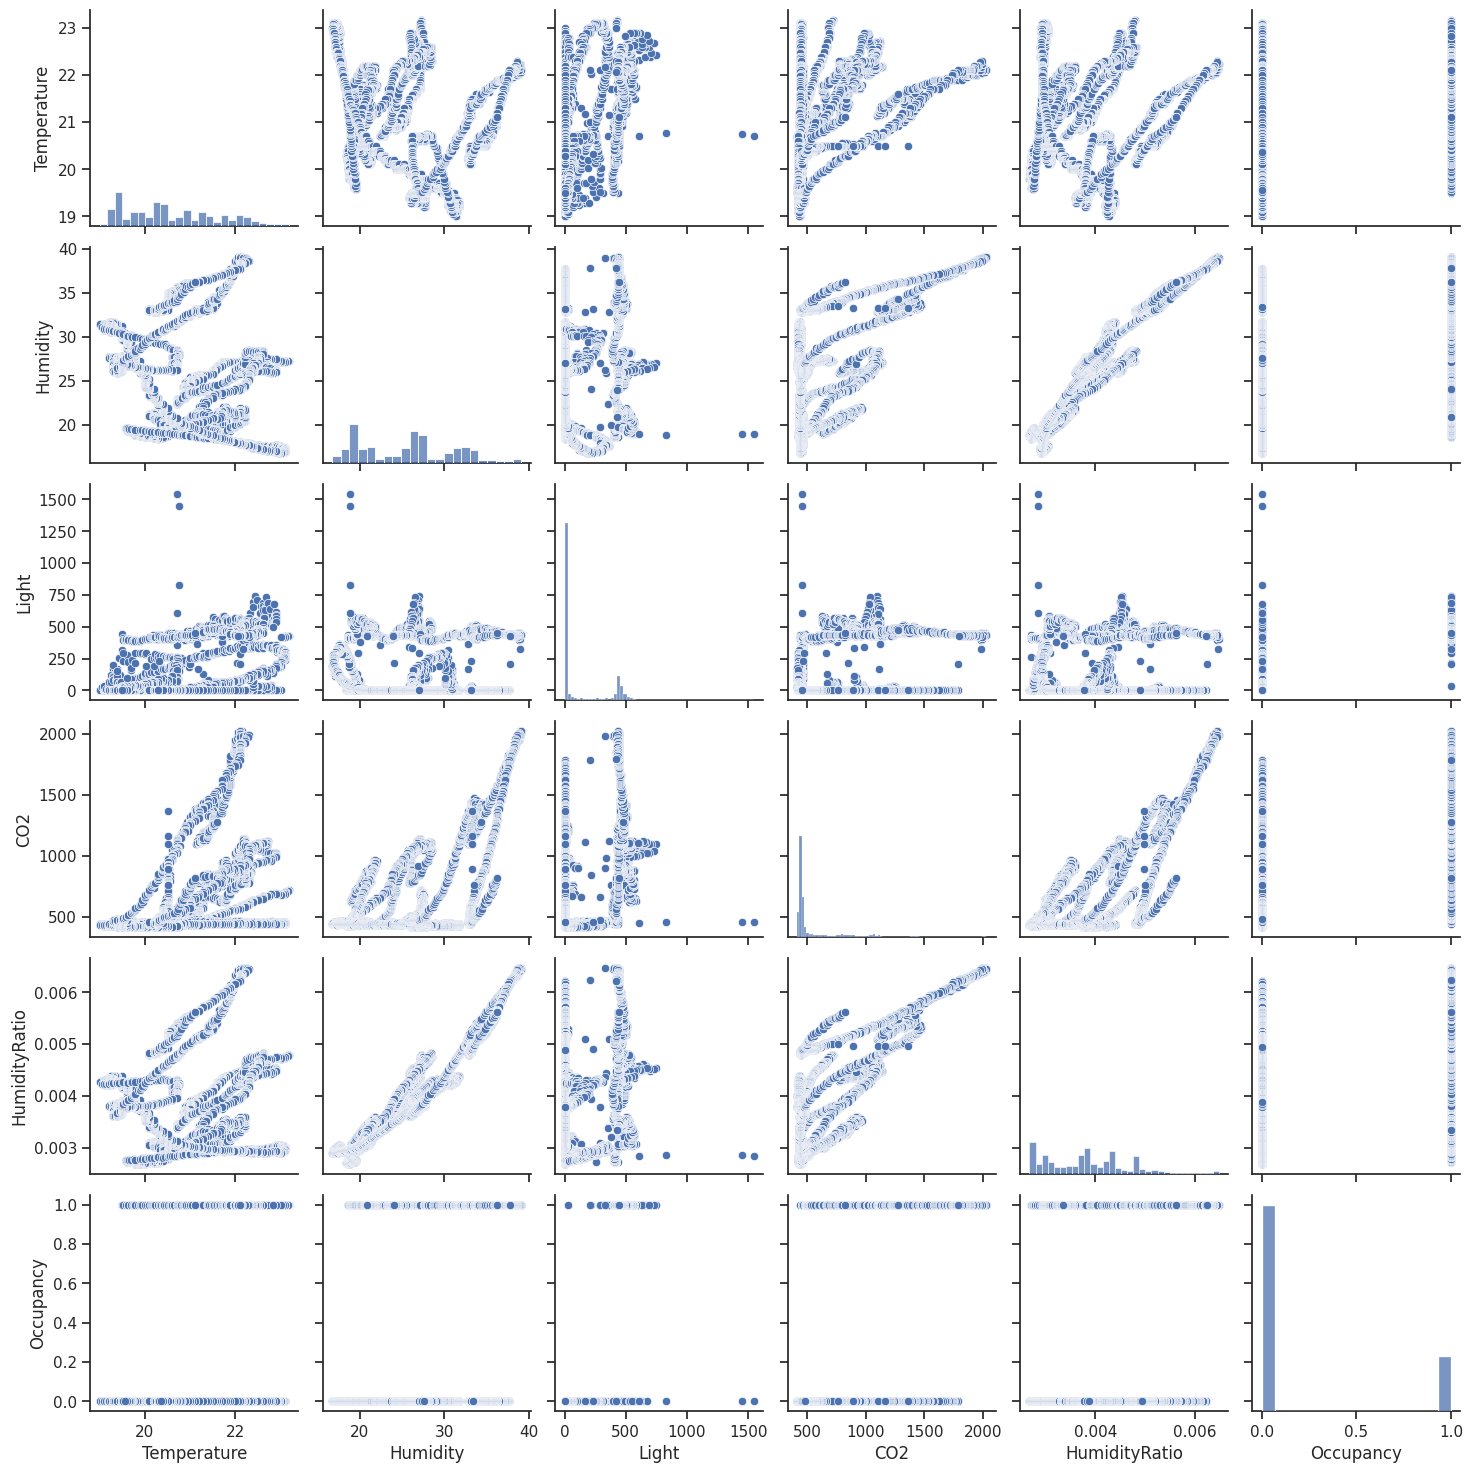

In [25]:
# парные диаграммы
sns.pairplot(data)

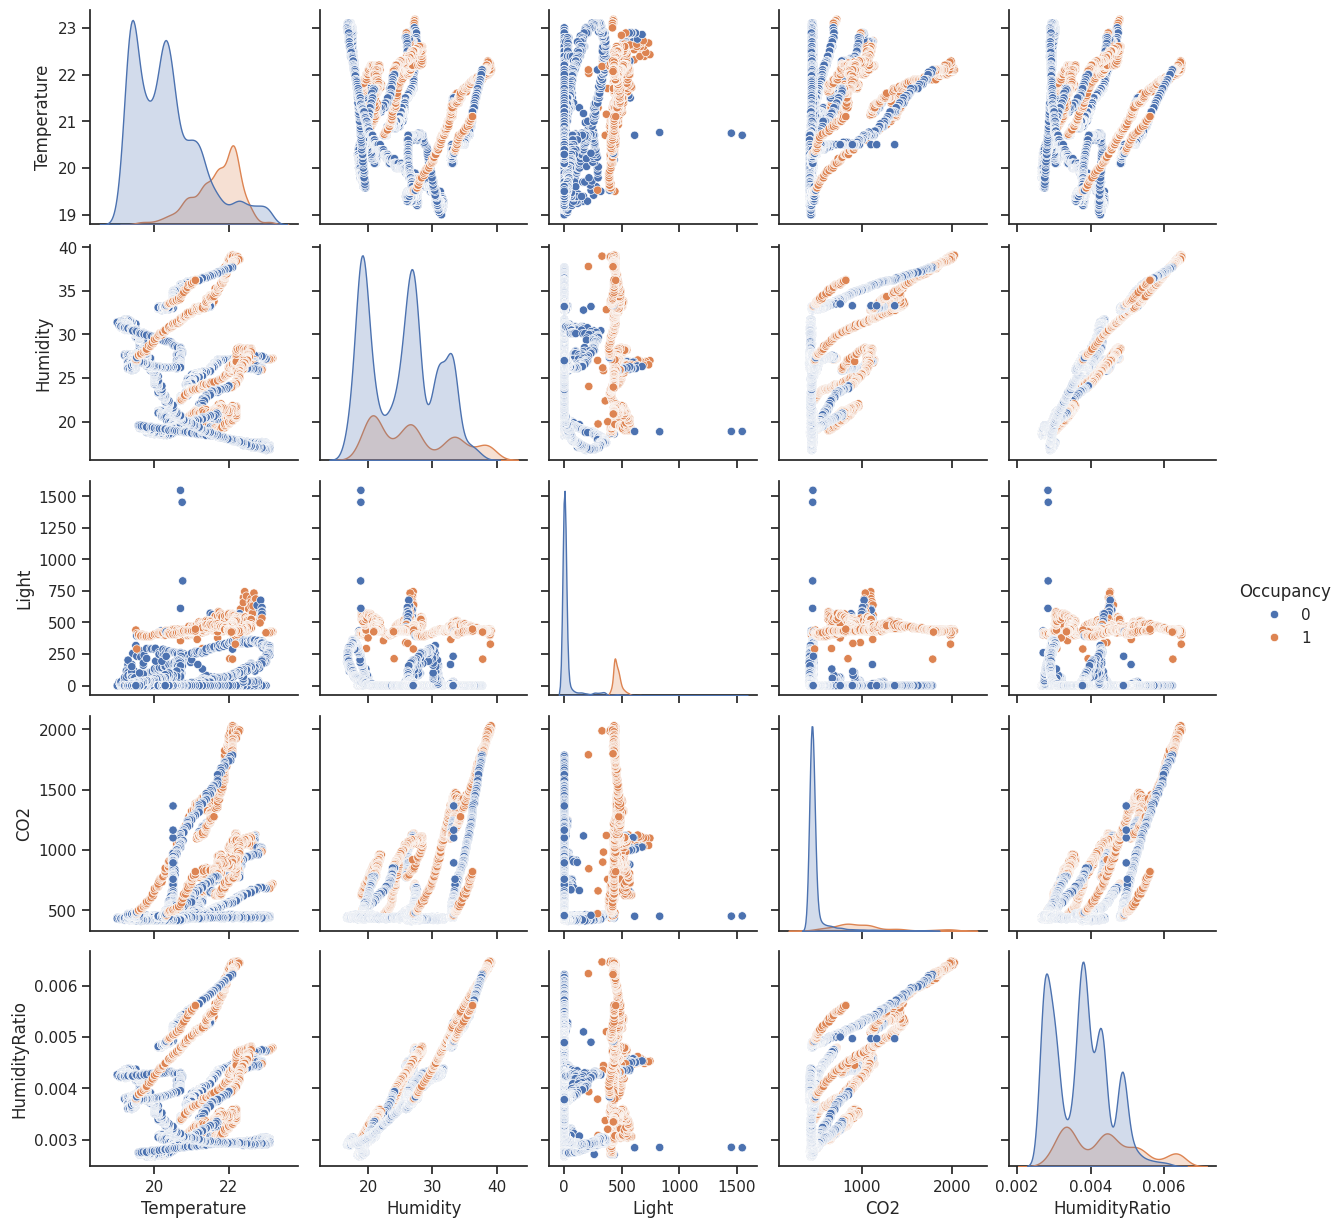

In [26]:
# парные диаграммы (группировка)
sns.pairplot(data, hue="Occupancy")

<Axes: xlabel='Humidity'>

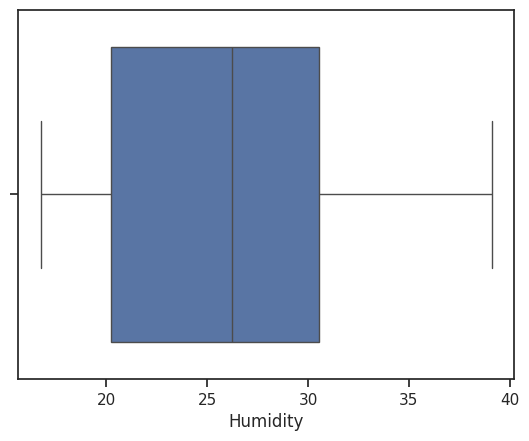

In [27]:
# ящик с усами вероятность распределение
sns.boxplot(x=data['Humidity'])

<Axes: ylabel='Humidity'>

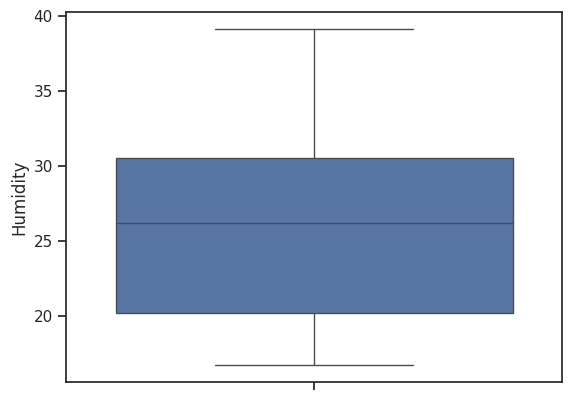

In [28]:
# по вретикали
sns.boxplot(y=data['Humidity'])

<Axes: xlabel='Occupancy', ylabel='Humidity'>

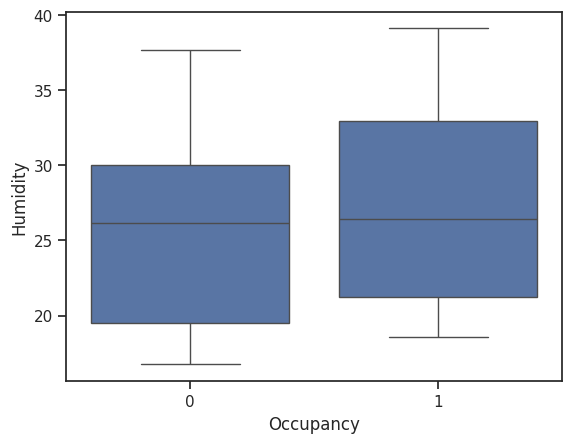

In [29]:
# группировка
sns.boxplot(x='Occupancy', y='Humidity', data=data)

/tmp/ipykernel_1332/3137546359.py:5: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(data['Humidity'], ax=ax[1])


<Axes: xlabel='Humidity', ylabel='Density'>

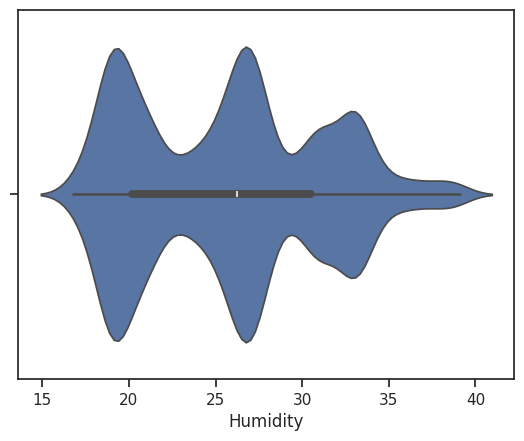

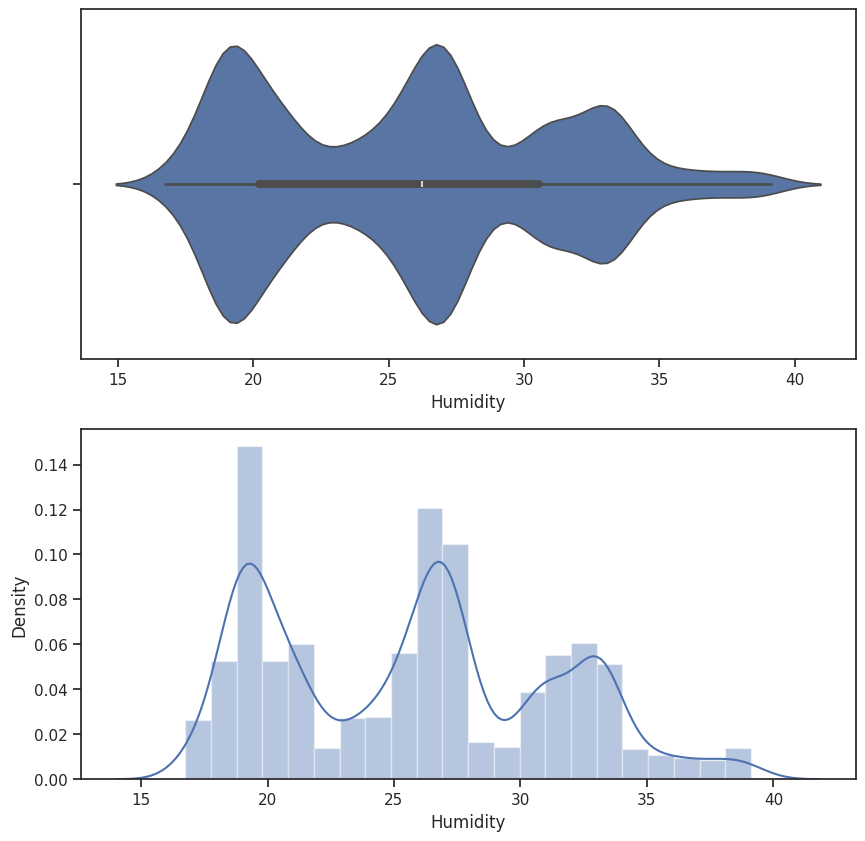

In [30]:
# violin plot
sns.violinplot(x=data['Humidity'])
fig, ax = plt.subplots(2, 1, figsize=(10,10))
sns.violinplot(ax=ax[0], x=data['Humidity'])
sns.distplot(data['Humidity'], ax=ax[1])

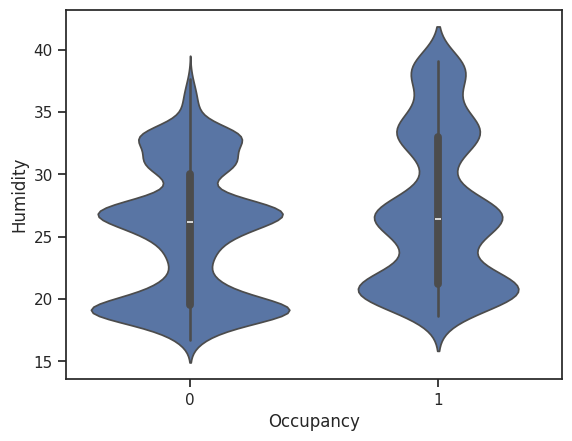

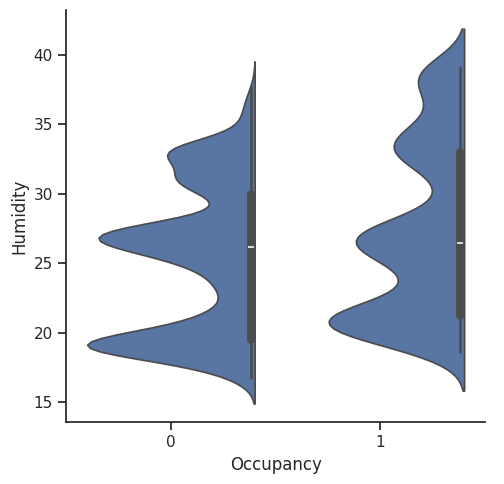

In [31]:
# Группировка
sns.violinplot(x='Occupancy', y='Humidity', data=data)
sns.catplot(y='Humidity', x='Occupancy', data=data, kind="violin", split=True)


<Axes: >

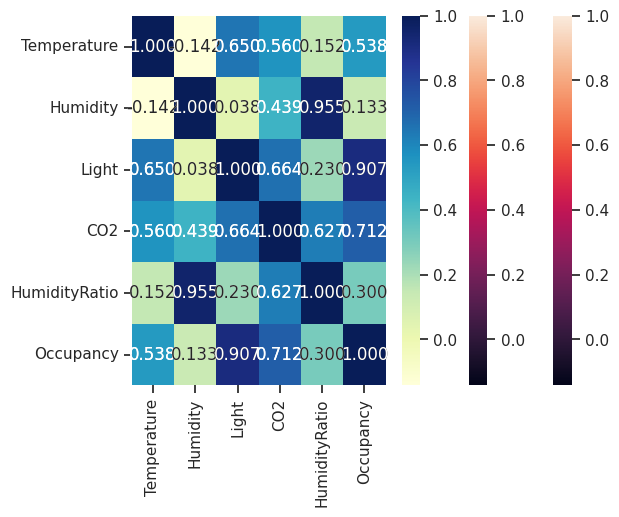

In [32]:
del data['date']
data.corr()
sns.heatmap(data.corr())
# Вывод значений в ячейках
sns.heatmap(data.corr(), annot=True, fmt='.3f')
# Изменение цветовой гаммы
sns.heatmap(data.corr(), cmap='YlGnBu', annot=True, fmt='.3f')
